## Regresija na computer hardware datasetu
Regresijski problem u ovom projektu se odnosi na predikciju relativnih performansi procesora na osnovu hardverskih specifikacija. Ciljna varijabla naziva se PRP (published relative performance) u ovom datasetu, koja je kontinuirana numerička varijabla. Krenut ćemo od linearne regresije sa više promjenljivih sve do polinomne regresije sa regularizacijom.
Prije toga učitat ćemo dataset, a zatim ćemo ga analizirati i uraditi preprocesiranje podataka.

Atributi koji se nalaze u datasetu pod skraćenicama imaju sljedeća značenja:
- MYCT: machine cycle time u nanosekundama
- MMIN/MMAX: minimum/maximum main memory u kilobajtima
- CACH: cache memory u kilobajtima
- CHMIN/CHMAX: minimum/maximum channels

In [88]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



data_path = Path(".") / "machine.data"
column_names = ['vendor_name', 'model_name', 'MYCT', 'MMIN',
                'MMAX', 'CACH', 'CHMIN', 'CHMAX', 'PRP', 'ERP']
data = pd.read_csv(data_path, header=None, names=column_names)
data.head(10)



,vendor_name,model_name,MYCT,MMIN,MMAX,CACH,CHMIN,CHMAX,PRP,ERP
0,adviser,32/60,125,256,6000,256,16,128,198,199
1,amdahl,470v/7,29,8000,32000,32,8,32,269,253
2,amdahl,470v/7a,29,8000,32000,32,8,32,220,253
3,amdahl,470v/7b,29,8000,32000,32,8,32,172,253
4,amdahl,470v/7c,29,8000,16000,32,8,16,132,132
5,amdahl,470v/b,26,8000,32000,64,8,32,318,290
6,amdahl,580-5840,23,16000,32000,64,16,32,367,381
7,amdahl,580-5850,23,16000,32000,64,16,32,489,381
8,amdahl,580-5860,23,16000,64000,64,16,32,636,749
9,amdahl,580-5880,23,32000,64000,128,32,64,1144,1238


Sada ćemo očistiti dataset od atributa koji nisu pogodni za treniranje modela. Nama je zadatak predikcija PRP pa zato prvo što ćemo morati ukloniti je očito ERP atribut jer je on procjena našeg PRP koji su autori originalnog rada dodali u dataset na osnovu njihove predikcije. Zatim, uklonit ćemo i kategoričke atribute vendor_name i model_name. Atribut model_name ima veliki broj jedinstvenih vrijednosti pa služi kao neka vrsta identifikatora i njegovo zadržavanje bi natjeralo model da nauči napamet po tim specifikacijama i ne bi se fokusirao na karakteristike koje su bitnije. Atribut vendor_name uklanjamo jer želimo natjerati model da se fokusira na fizičke karakteristike hardvera umjesto na proizvođača.

In [89]:
print("Dimenzije dataseta su: ", data.shape)
no_of_duplicates = data.duplicated().sum()
print("Broj duplikata: ", no_of_duplicates)
missing_values = data.isnull().sum()
print("Broj nedostajucih vrijednosti\n", missing_values)

Dimenzije dataseta su:  (209, 10)
Broj duplikata:  0
Broj nedostajucih vrijednosti
 vendor_name    0
model_name     0
MYCT           0
MMIN           0
MMAX           0
CACH           0
CHMIN          0
CHMAX          0
PRP            0
ERP            0
dtype: int64


Vidimo da u datasetu nema duplikata i nema nedostajućih vrijednosti. Možemo nastaviti sa daljom analizom

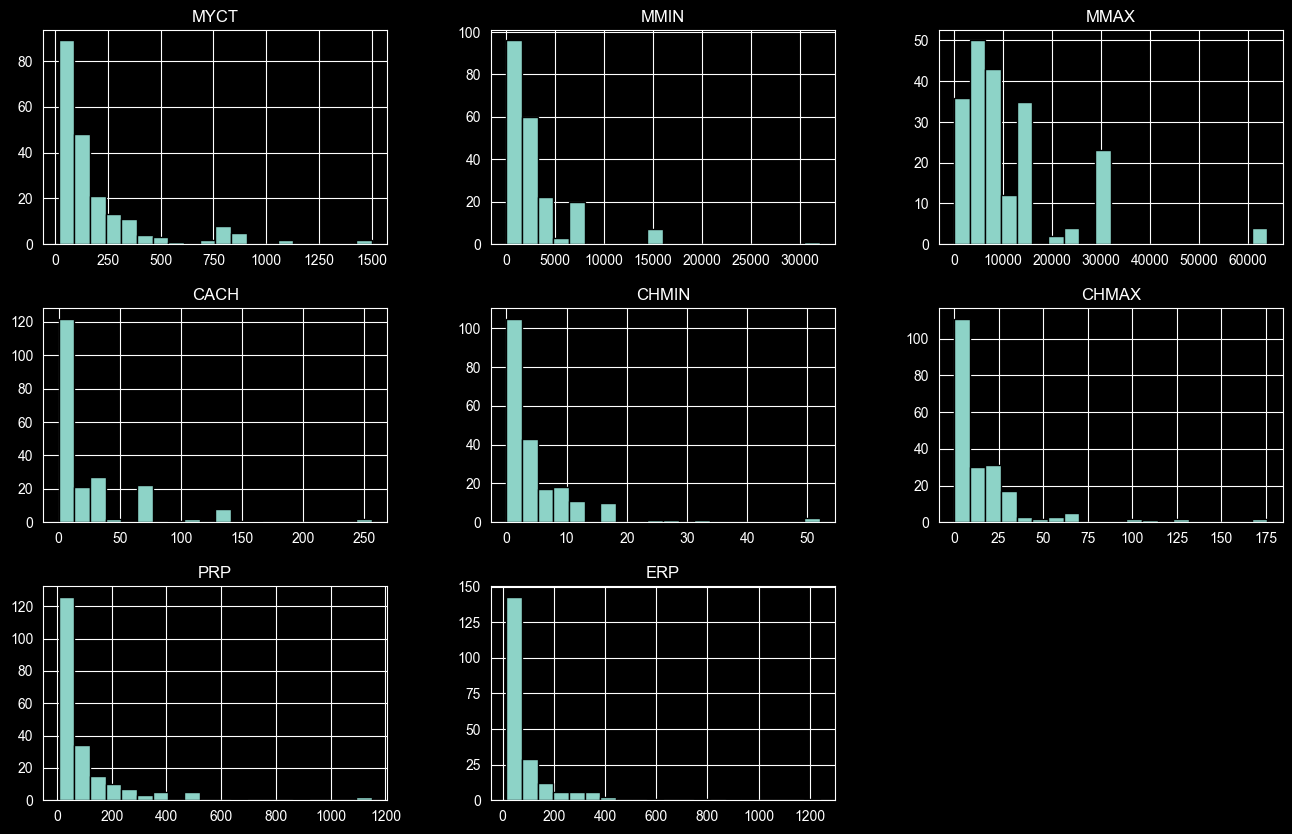

In [90]:
data.hist(bins=20, figsize=(16, 10), edgecolor='black')
plt.show()

- Uočavamo da većina atributa, kao i ciljna varijabla PRP, ima right skew. Ovo znači da dataset sadrži veliki broj procesora sa slabijim performansama i mali broj sa vrlo jakim performansama.

In [91]:
corr_mat = data.corr(numeric_only=True)
corr_mat

,MYCT,MMIN,MMAX,CACH,CHMIN,CHMAX,PRP,ERP
MYCT,1.000000,-0.335642,-0.378561,-0.321000,-0.301090,-0.250502,-0.307099,-0.288396
MMIN,-0.335642,1.000000,0.758157,0.534729,0.517189,0.266907,0.794931,0.819292
MMAX,-0.378561,0.758157,1.000000,0.537990,0.560513,0.527246,0.863004,0.901202
CACH,-0.321000,0.534729,0.537990,1.000000,0.582245,0.487846,0.662641,0.648620
CHMIN,-0.301090,0.517189,0.560513,0.582245,1.000000,0.548281,0.608903,0.610580
CHMAX,-0.250502,0.266907,0.527246,0.487846,0.548281,1.000000,0.605209,0.592156
PRP,-0.307099,0.794931,0.863004,0.662641,0.608903,0.605209,1.000000,0.966472
ERP,-0.288396,0.819292,0.901202,0.648620,0.610580,0.592156,0.966472,1.000000


Iz matrice korelacije možemo uočiti sljedeće stvari:
- MYCT ima negativnu korelaciju sa PRP. Ovo je i logično jer je MYCT machine cycle time, pa što je taj broj manji to je procesor brži. Kako on opada, PRP raste.
- MMIN i MMAX su u visokoj korelaciji sa PRP, ali i jedno s drugim. Ovo nas navodi na to da je možda prisutna multikolinearnost, ali svakako vidimo da su minimum main memory i maximum main memory kontekstualno povezani. Provjerit ćemo kasnije postoji li multikolinearnost statističkim testovima.
- Korelacija PRP i ERP je očekivano visoka jer je ERP procjena atributa PRP, nju zanemarujemo svakako.
- CHMIN, CHMAX i CACH su isto u visokoj korelaciji sa PRP što ih čini značajnim u našem modelu regresije.

Ispitajmo sada da li je prisutna multikolinearnost VIF (variance inflation factor) testom . Ideja za testiranje i tumačenje rezultata testa su u skladu sa provjerenim statističkim i data science stranicama:
- https://statisticsbyjim.com/regression/multicollinearity-in-regression-analysis/
- https://www.datacamp.com/tutorial/variance-inflation-factor

In [92]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

cols = ['MYCT', 'MMIN', 'MMAX', 'CACH', 'CHMIN', 'CHMAX']
x_vif = data[cols]


x_with_const = add_constant(x_vif)


vif_data = pd.DataFrame()
vif_data['Feature'] = x_with_const.columns
vif_data['VIF'] = [variance_inflation_factor(x_with_const.values, i)
                   for i in range(x_with_const.shape[1])]
print(vif_data)

  Feature       VIF
0   const  3.758925
1    MYCT  1.201644
2    MMIN  2.902002
3    MMAX  3.274002
4    CACH  1.858349
5   CHMIN  1.966234
6   CHMAX  1.891392


Na osnovu rezultata, možemo uočiti da nijedan faktor ne prelazi 5 čime zaključujemo da ne postoji naznaka multikolinearnosti. Iako je korelacija između MMIN i MMAX visoka, ovaj test potvrđuje da svaka od varijabli doprinosi modelu pa ih nećemo izbaciti niti mijenjati.

Ovim smo završili sa preprocesiranjem i analizom podataka. Prelazimo na izbor i treniranje modela.

In [93]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


X = data.drop(columns=['ERP', 'PRP', 'vendor_name', 'model_name'])
y = data['PRP']

y_binned = pd.qcut(y, q=4, labels=False, duplicates='drop')

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y_binned,
    shuffle=True
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Kao što već znamo, dataset je mali i sadrži ekstremne vrijednosti pa postoji opasnost da podjela podataka bude takva da ekstremni slučajevi odu samo u trening ili samo u test. Time bismo dobili veliku razliku pri testiranju, a to vodi ka lošoj generalizaciji modela.  Da bi raspodjela po trening i test setu bila ravnomjerna, uradili smo stratify po y. Kako ovo nije klasifikacioni problem (y je kontinuirana numerička varijabla), to smo pomoću biblioteke pandas podijelili y u 4 kvartila (bina) i simulirali podjelu y u klase tj. binove.
Dalje, primijenili smo StandardScaler standardizaciju zbog prirode naših atributa (značajno se razlikuju u mjernim jedinicima i rasponu vrijednosti).

In [94]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

model_lin_reg = LinearRegression()
model_lin_reg.fit(X_train_scaled, y_train)

y_train_pred = model_lin_reg.predict(X_train_scaled)
y_test_pred = model_lin_reg.predict(X_test_scaled)

train_metrics = {
    "R2": r2_score(y_train, y_train_pred),
    "RMSE": np.sqrt(mean_squared_error(y_train, y_train_pred)),
    "MAE": mean_absolute_error(y_train, y_train_pred),
    "MSE" : mean_squared_error(y_train, y_train_pred),
}
test_metrics = {
    "R2": r2_score(y_test, y_test_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_test_pred)),
    "MAE": mean_absolute_error(y_test, y_test_pred),
    "MSE" : mean_squared_error(y_test, y_test_pred),
}

print("Metrike na trening skupu: ")
for naziv, vrijednost in train_metrics.items():
    print(f"{naziv}: {vrijednost:.4f}")

print("\nMetrike na test skupu:")
for naziv, vrijednost in test_metrics.items():
    print(f"{naziv}: {vrijednost:.4f}")


Metrike na trening skupu: 
R2: 0.8629
RMSE: 61.6578
MAE: 37.3023
MSE: 3801.6799

Metrike na test skupu:
R2: 0.8575
RMSE: 53.2154
MAE: 38.9920
MSE: 2831.8737


### Analiza rezultata dobijenih linearnom regresijom
Vidimo da je na treningu oko 86% varijanse ciljne varijable objašnjeno ovim modelom, dok je na testu oko 85%. Razlika je minimalna, što je dobar znak da model nije naučio podatke napamet.
RMSE nam govori da model u prosjeku promaši stvarnu vrijednost za oko 61 jedinica na treningu, a oko 53 na testu. Ovo je zanimljivo jer inače očekujemo veću grešku na skupu neviđenih tj. testnih podataka. Jedan od mogućih razloga  je da su ekstremne vrijednosti više prisutne u trening skupu.
 MAE pokazuje da u prosjeku model promaši za oko 38 jedinica na oba skupa, što ukazuje na stabilnu prosječnu grešku.
 Na kraju, za MSE iako je teško tumačiti ovako pojedinačno dobijene vrijednosti jer predstavljaju prosjek kvadrata grešaka, uočavamo da je na testu manja vrijednost što sugeriše da u ovom slučaju model ne pravi velike greške na testnom skupu.

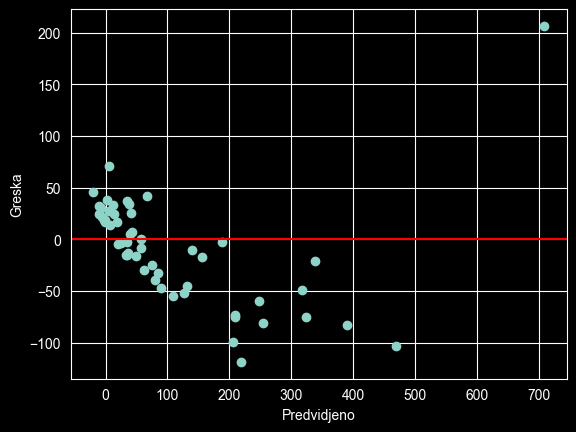

In [95]:
residuals = y_test - y_test_pred

plt.scatter(y_test_pred, residuals)
plt.axhline(y=0, color='r')
plt.xlabel('Predvidjeno')
plt.ylabel('Greska')
plt.show()

Na grafiku reziduala možemo uočiti nelinearan trend, tj. vidimo da model potcijenjuje performanse na ekstremnim vrijednostima, a precijenjuje u srednjem opsegu. Upravo zbog ovoga, isprobat ćemo malo složenije modele počevši od polinomne regresije.
Prije toga, primijetili smo da postoje ekstremne vrijednosti. One utiču na naš model i uzrokuju veće greške u predikciji.

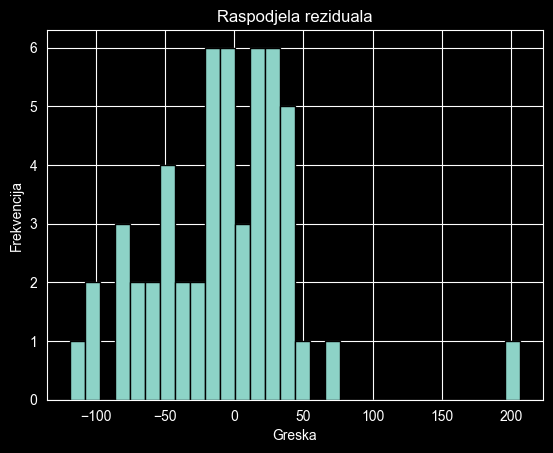

Skew  0.8920111651668038


In [96]:
plt.hist(residuals, bins=30, edgecolor='black')

plt.title('Raspodjela reziduala')
plt.xlabel('Greska')
plt.ylabel('Frekvencija')
plt.show()

print("Skew ", residuals.skew())

Gledajući histogram ovih reziduala, možemo uočiti da postoji blagi right skew što potvrđuje vrijednost skewness-a od 0.89.
Ovo znači da naš model dobro predviđa procesore nižih i srednjih performansi, ali griješi tj. potcijenjuje kod ekstremnih vrijednosti što stvara ovaj right skew (desni rep). Znamo da linearna regresija pretpostavlja normalnu distribuciju reziduala. Stoga, model linearne regresije bi se mogao poboljšati nekom od transformacija za right skewed podatke, poput sqrt/log transformacije,  ciljne varijable PRP (izvor: https://medium.com/@gerardlouishowan/un-skewing-data-how-to-boost-regression-accuracy-with-transformations-1d34e8e4950a).

Sada ćemo istrenirati model polinomne regresije

In [97]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)

y_train_pred = model_poly.predict(X_train_poly)
y_test_pred = model_poly.predict(X_test_poly)

train_metrics = {
    "R2": r2_score(y_train, y_train_pred),
    "RMSE": np.sqrt(mean_squared_error(y_train, y_train_pred)),
    "MAE": mean_absolute_error(y_train, y_train_pred),
    "MSE" : mean_squared_error(y_train, y_train_pred),
}
test_metrics = {
    "R2": r2_score(y_test, y_test_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_test_pred)),
    "MAE": mean_absolute_error(y_test, y_test_pred),
    "MSE" : mean_squared_error(y_test, y_test_pred),
}
print("Metrike na trening skupu POLINOMNA REG: ")
for naziv, vrijednost in train_metrics.items():
    print(f"{naziv}: {vrijednost:.4f}")

print("\nMetrike na test skupu POLINOMNA REG:")
for naziv, vrijednost in test_metrics.items():
    print(f"{naziv}: {vrijednost:.4f}")


Metrike na trening skupu POLINOMNA REG: 
R2: 0.9650
RMSE: 31.1621
MAE: 21.6386
MSE: 971.0752

Metrike na test skupu POLINOMNA REG:
R2: 0.8934
RMSE: 46.0313
MAE: 28.5116
MSE: 2118.8813


### Analiza rezultata dobijenih polinomnom regresijom
Vidimo da je na treningu oko 96.5% varijanse ciljne varijable objašnjeno ovim modelom, dok je na testu oko 89%. Razlika je primjetna što ukazuje na to da model pokazuje znakove overfittinga.
RMSE nam govori da model u prosjeku promaši stvarnu vrijednost za oko 31 jedinicu na treningu, a oko 46 na testu. Ovo je bolje u odnosu na linearnu regresiju na trening podacima, ali greška je ovdje primjetno veća na testnim podacima u odnosu na trening.
MAE je porastao sa oko 21.6 na 28.51 što opet ukazuje na pogoršanje performansi na testnom skupu.
 Na kraju, MSE je značajno veći na testnom skupu nego na treningu, što opet znači da model pravi veće greške na neviđenim podacima.

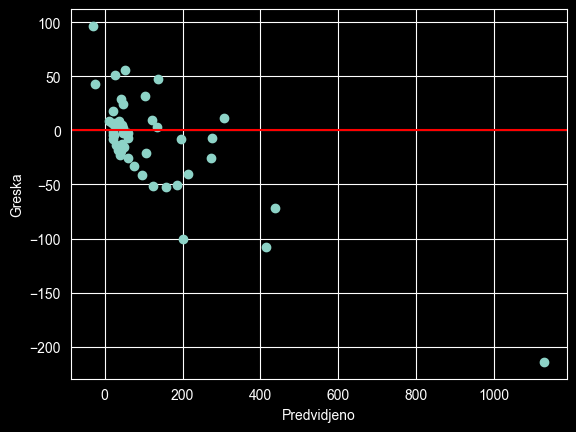

In [98]:
residuals = y_test - y_test_pred

plt.scatter(y_test_pred, residuals)
plt.axhline(y=0, color='r')
plt.xlabel('Predvidjeno')
plt.ylabel('Greska')
plt.show()

#### Sa ovog scatter plota možemo primjetiti:
- tačke koje su lijevo na početku su relativno blizu crvene linije i ravnomjerno raspoređene, ali kako se krećemo prema većim vrijednostima udesno (tj. što su jači procesori) to je model značajno precijenio njihove vrijednosti. Ovaj grafik je značajan indikator da se desio overfitting i da se model pokušao prilagoditi šumovima na treningu, a kao rezultat na testu smo dobili ova odstupanja.
 ### Zaključak za polinomnu regresiju
 Iako polinomna regresija postiže odlične rezultate na treningu (mnogo bolje od linearne regresije), metrike na testnom skupu i gornji grafik ukazuju na to da model ne generalizuje dobro na neviđenim podacima i da je došlo do blagog overfittinga. Upravo iz ovog razloga ćemo probati polinomnu regresiju sa L2 regularizacijom.

In [99]:
alpha_values = [0.1, 1.0, 10.0, 20.0, 40.0, 50.0, 100.0]

results = []

for a in alpha_values:
    poly_ridge = Ridge(alpha=a)
    poly_ridge.fit(X_train_poly, y_train)
    y_train_pred = poly_ridge.predict(X_train_poly)
    y_test_pred = poly_ridge.predict(X_test_poly)

    r2_train = r2_score(y_train, y_train_pred)
    r2_test = r2_score(y_test, y_test_pred)

    results.append({
        "Alpha" : a,
        "Train r2" : r2_train,
        "Test r2" : r2_test,
        "Razlika" : r2_train - r2_test
    })

df_res = pd.DataFrame(results)
display(df_res.round(4))

,Alpha,Train r2,Test r2,Razlika
0,0.1,0.9649,0.8955,0.0694
1,1.0,0.9644,0.9022,0.0622
2,10.0,0.9612,0.9203,0.0408
3,20.0,0.9578,0.9298,0.0281
4,40.0,0.9511,0.9395,0.0116
5,50.0,0.9478,0.9421,0.0056
6,100.0,0.9324,0.9455,-0.0132


Kako bismo riješili problem overfittinga, uveli smo L2 regularizaciju (tzv. Ridge regresiju). Parametar alpha je ključan jer on kontroliše jačinu regularizacije. Tačnije, alpha je hiperparametar kojim kažnjavamo velike koeficijente i spriječavamo da se model previše prilagodi šumovima. Da bismo našli koja je vrijednost najbolja, testirali smo model sa nizom vrijednosti alpha_values. Uočavamo da je najmanja razlika u R2 scoreu za vrijednost alpha = 50.0. Shodno tome, biramo nju kao optimalnu za naš model.

In [100]:
poly_ridge = Ridge(alpha=50.0)
poly_ridge.fit(X_train_poly, y_train)
y_train_pred = poly_ridge.predict(X_train_poly)
y_test_pred = poly_ridge.predict(X_test_poly)

train_metrics = {
    "R2": r2_score(y_train, y_train_pred),
    "RMSE": np.sqrt(mean_squared_error(y_train, y_train_pred)),
    "MAE": mean_absolute_error(y_train, y_train_pred),
    "MSE" : mean_squared_error(y_train, y_train_pred),
}
test_metrics = {
    "R2": r2_score(y_test, y_test_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_test_pred)),
    "MAE": mean_absolute_error(y_test, y_test_pred),
    "MSE" : mean_squared_error(y_test, y_test_pred),
}
print("Metrike na trening skupu POLINOMNA RIDGE: ")
for naziv, vrijednost in train_metrics.items():
    print(f"{naziv}: {vrijednost:.4f}")

print("\nMetrike na test skupu POLINOMNA RIDGE:")
for naziv, vrijednost in test_metrics.items():
    print(f"{naziv}: {vrijednost:.4f}")

Metrike na trening skupu POLINOMNA RIDGE: 
R2: 0.9478
RMSE: 38.0462
MAE: 25.7853
MSE: 1447.5156

Metrike na test skupu POLINOMNA RIDGE:
R2: 0.9421
RMSE: 33.9138
MAE: 23.5553
MSE: 1150.1444


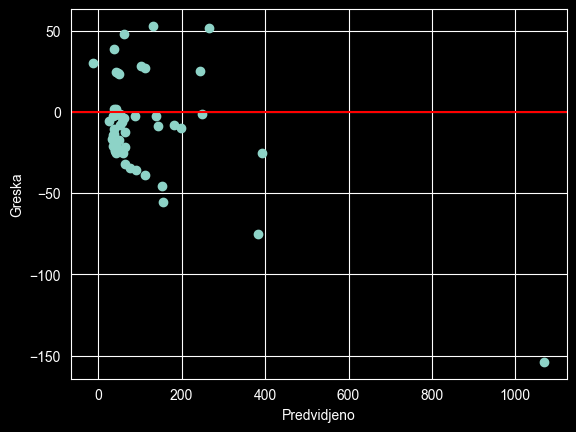

In [101]:
residuals = y_test - y_test_pred

plt.scatter(y_test_pred, residuals)
plt.axhline(y=0, color='r')
plt.xlabel('Predvidjeno')
plt.ylabel('Greska')
plt.show()

Uočimo da iako je naš model regularizacijom bolje obuzdao ekstremne vrijednosti u odnosu na običnu polinomnu regresiju, grafik ipak pokazuje da model teži blagom precijenjivanju stvarnih performansi. To je direktna posljedica regularizacije koje smo uveli, ali je model sada stabilniji na neviđenim podacima. Dakle, naš model nije savršen, ali je najstabilniji do sad. Pogledajmo još i histogram reziduala.

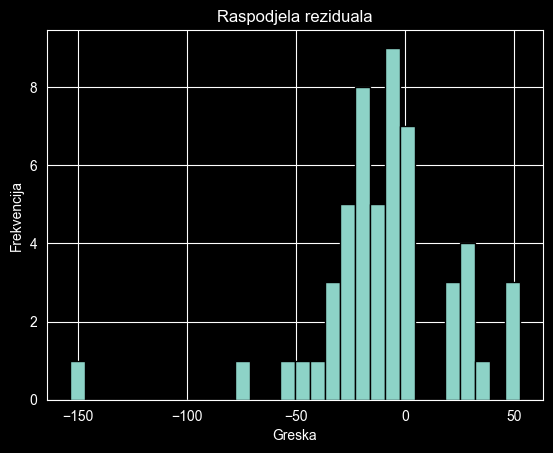

Skew  -1.385073932942355


In [102]:
plt.hist(residuals, bins=30, edgecolor='black')

plt.title('Raspodjela reziduala')
plt.xlabel('Greska')
plt.ylabel('Frekvencija')
plt.show()

print("Skew ", residuals.skew())

- Uočavamo left skew što potvrđuje i skew reziduala od -1.385. Veliki negativni reziduali znače da je predviđena vrijednost veća od stvarne. To potvrđuje da model precijenjuje stvarne performanse procesora.

### Analiza rezultata dobijenih polinomnom regresijom sa L2 regularizacijom
Nakon uvođenja regularizacije, vidimo da je na treningu oko 94.7% varijanse ciljne varijable objašnjeno modelom dok je na testu taj procenat skoro pa identičan, 94.2%. Razlika između treninga i testa je zaista minimalna, što je ukazuje na dobru generalizaciju modela i značajno smanjenje overfittinga.
RMSE govori da model u prosjeku promaši za oko 38 jedinica na treningu, a oko 34 na testu (mnogo bolje u odnosu na linearnu regresiju). Ovo je veliko poboljšanje u odnosu na prethodne modele. MAE takođe ukazuje da je prosječna greška stabilna i manja.
Na kraju, MSE na testnom skupu je znatno manji u odnosu na oba prethodna modela, što potvrđuje da je model postao otporniji na ekstremne vrijednosti.
### Zaključak za polinomnu regresiju sa L2 regularizacijom
Polinoma regresija sa L2 regularizacijom se pokazala kao najbolji model. Na osnovu prethodne navedene analize metrika, vidimo da smo dobili model koji je stabilan i precizan na neviđenim podacima.

## Finalni zaključak

U ovom projektu analizirali smo problem predikcije performansi procesora. Primijenili smo različite regresijske modele, počevši od linearne regresije sa više promjenljivih. Ovaj model je dao solidne rezultate, ali nam je ukazao na to da postoji nelinearan trend i  problemi sa ekstremnim vrijednostima. Zatim smo uveli polinomnu regresiju koja se bolje prilagodila nelinearnom odnosu varijabli, ali se pojavio problem overfittinga koji je čest kod polinomne regresije i ekstremnih vrijednosti. Da bismo ovo riješili, uveli smo L2 regularizaciju tzv. Ridge regresiju, koja je obuzdala utjecaj ekstremnih vrijednosti i smanjila overfitting. Odabrani hiperparametar alpha=50.0 pokazao se optimalnim i dao je vrlo slične rezultate na treningu i testu. Ovo ukazuje na dobru generalizaciju modela. Ipak, primjetili smo da model blago precijenjuje stvarne performanse procesora, pogotovo za veće vrijednosti ciljne varijable. Kako smo na početku uočili da ciljna varijabla ima right skew, ovdje bi se njenom transformacijom koristeći log/sqrt transformaciju za right skewed podatke, potencijalno mogla poboljšati preciznost modela.
### Zaključak
Model polinomne regresije sa L2 regularizacijom se pokazao kao najbolji model, pružajući stabilnost i preciznost.